# Assignment 4: Breast Cancer Diagnosis Classification

**Name :- *Shravani Minache*
**Div:-A  Batch:-A3**
**PRN :- 202401040304**

**Aim:** Prepare an official benchmark dataset, train four classification algorithms (SVM, CART Decision Tree, KNN and Naive Bayes) and compare their performance.

**Dataset:** `wdbc.data`, the Breast Cancer Wisconsin (Diagnostic) Data Set (WDBC) downloaded from the UCI Machine Learning Repository
(Wolberg, Street & Mangasarian, 1995; https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic, DOI 10.24432/C5DW2B, CC BY 4.0).
The file has no header row, so the column names are taken from the accompanying `wdbc.names` description.

**Task:** Predict whether a breast mass is *Malignant* or *Benign* from 30 numeric features computed from a digitised image of a fine needle aspirate (FNA).

## 1. Import libraries

Import the libraries used for preprocessing, model training and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 2. Load and inspect the dataset

Load the UCI WDBC data and check its size, columns, missing values and diagnosis distribution.

In [2]:
# Look for wdbc.data in the data/ folder first, then next to the notebook
data_path = next((p for p in [Path("data/wdbc.data"), Path("wdbc.data")] if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Place wdbc.data in a 'data' folder next to this notebook (or beside it).")

# wdbc.data has no header: ID, Diagnosis, then 10 measurements x (mean, standard error, worst)
base_features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"
]
columns = (["Patient_ID", "Diagnosis"]
           + [f"{f}_mean" for f in base_features]
           + [f"{f}_se" for f in base_features]
           + [f"{f}_worst" for f in base_features])

df = pd.read_csv(data_path, header=None, names=columns)

# Use readable diagnosis labels instead of M / B codes
df["Diagnosis"] = df["Diagnosis"].map({"M": "Malignant", "B": "Benign"})

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("Data Type"))
display(df.isnull().sum().to_frame("Missing Values"))
display(df["Diagnosis"].value_counts().to_frame("Patient Count"))

Dataset shape: (569, 32)


,Patient_ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,Malignant,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,Malignant,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,Malignant,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,Malignant,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,Malignant,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,Data Type
Patient_ID,int64
Diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave_points_mean,float64


,Missing Values
Patient_ID,0
Diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave_points_mean,0


,Patient Count
Diagnosis,
Benign,357
Malignant,212


## 3. Data preprocessing

Remove the patient ID because it is only an identifier. This dataset has no missing values, but the same robust pipeline is used as a general template: fill numerical gaps with the median and categorical gaps with the most frequent value, scale numerical features and one-hot encode categorical features (the categorical branch is simply empty here).

In [3]:
X = df.drop(columns=["Diagnosis", "Patient_ID"])
y_text = df["Diagnosis"].astype(str).str.strip()

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Number of numerical features:", len(numeric_features))
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target classes:", list(target_encoder.classes_), "-> encoded as", list(range(len(target_encoder.classes_))))
print("Missing input values:", int(X.isna().sum().sum()))

Number of numerical features: 30
Numerical features: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Categorical features: []
Target classes: ['Benign', 'Malignant'] -> encoded as [0, 1]
Missing input values: 0


## 4. Split the dataset

Use an 80:20 train-test split. Stratification keeps the diagnosis class proportions similar in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 455
Testing records: 114


## 5. Define the classification models

All models use the same preprocessing pipeline so that the comparison is consistent.

In [5]:
models = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree (CART)": DecisionTreeClassifier(
        criterion="gini", max_depth=5, random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

pipelines = {
    name: Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

## 6. Train and evaluate

Evaluate the models on the test set. The positive class is **Malignant** (encoded as 1), so precision and recall describe how well malignant cases are detected. Log loss measures the quality of predicted probabilities; a lower value is better.

In [6]:
results = []
trained_models = {}
predictions = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

comparison = pd.DataFrame(results).sort_values(
    "F1-Score", ascending=False
).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.9737,1.0000,0.9286,0.9630,0.0822
1,K-Nearest Neighbors,0.9561,0.9744,0.9048,0.9383,0.4091
2,Naive Bayes,0.9211,0.9231,0.8571,0.8889,0.4999
3,Decision Tree (CART),0.9211,0.9459,0.8333,0.8861,1.0968


## 7. Performance comparison

Compare accuracy, precision, recall and F1-score across the four models. The second chart compares log loss.

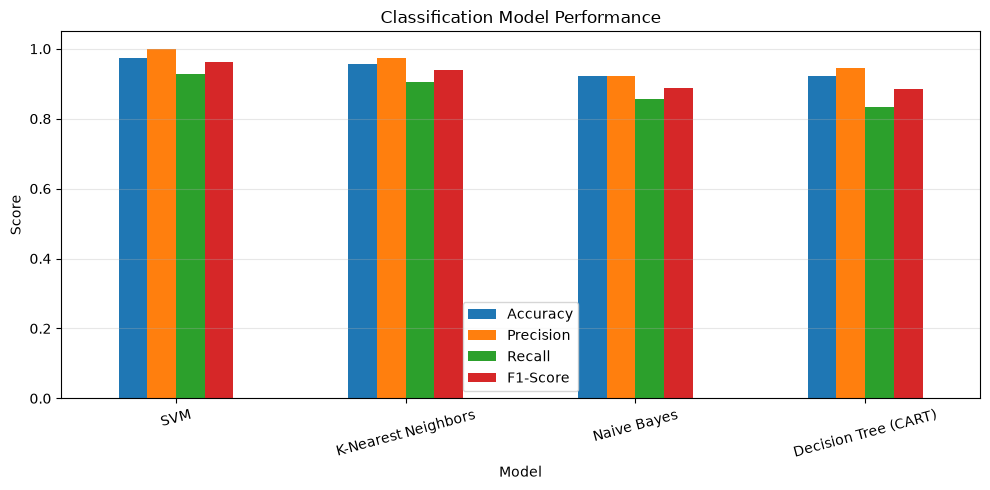

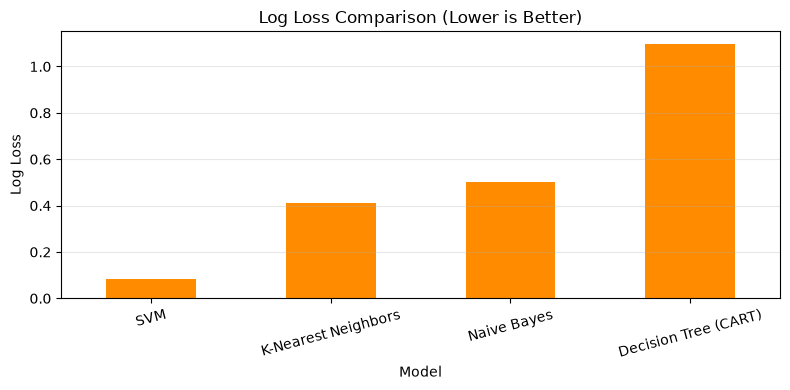

In [7]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=15
)
plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

comparison.set_index("Model")["Log Loss"].plot(
    kind="bar", figsize=(8, 4), color="darkorange"
)
plt.title("Log Loss Comparison (Lower is Better)")
plt.ylabel("Log Loss")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Confusion matrices

The confusion matrices show correct and incorrect predictions for both diagnosis classes.

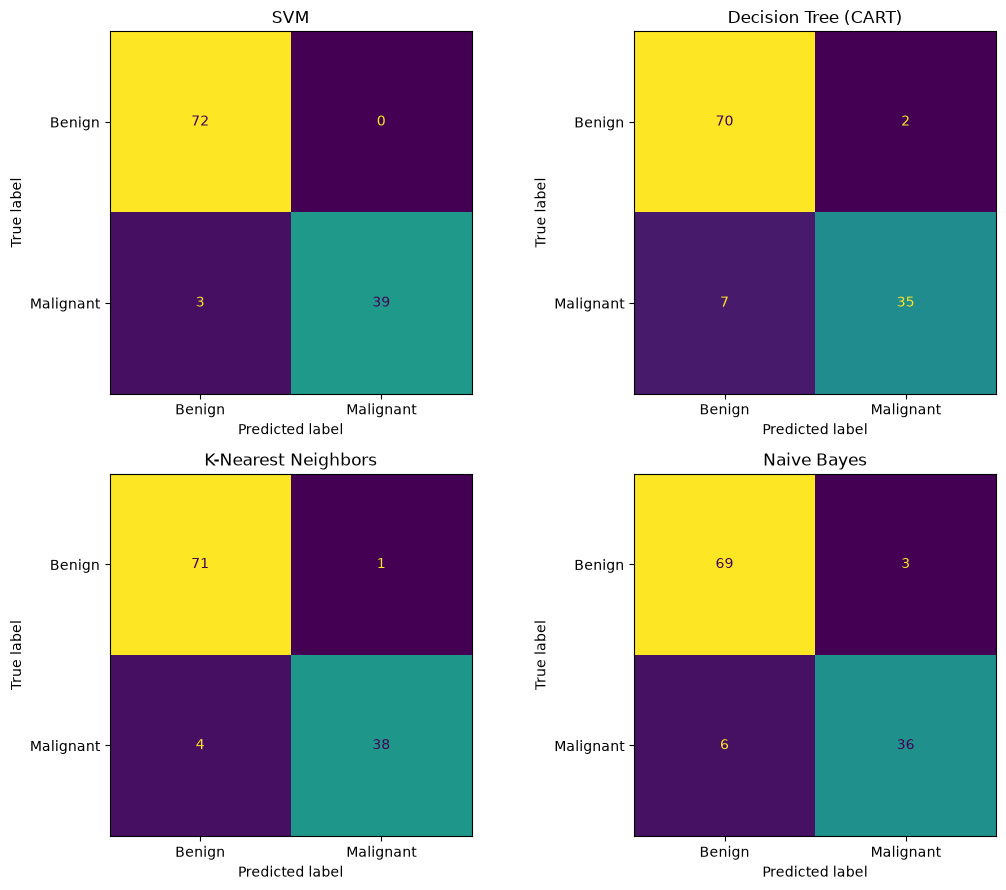

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=target_encoder.classes_
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 9. Classification reports

The reports show precision, recall and F1-score for each class separately.

In [9]:
for name, y_pred in predictions.items():
    print(f"--- {name} ---")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=[str(c) for c in target_encoder.classes_],
        zero_division=0
    ))

--- SVM ---
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

--- Decision Tree (CART) ---
              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94        72
   Malignant       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92      0.92       114

--- K-Nearest Neighbors ---
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weigh

## 10. Result and conclusion

The comparison table and charts show how SVM, CART Decision Tree, KNN and Naive Bayes perform on the Breast Cancer Wisconsin (Diagnostic) data. Accuracy gives the overall proportion of correct predictions, while precision, recall and F1-score give a closer view of the positive (Malignant) class. Recall is especially important in this medical setting because a missed malignant case (false negative) is costlier than a false alarm. Log loss evaluates the quality of predicted probabilities.

In [10]:
best_f1 = comparison.iloc[0]
best_ll = comparison.sort_values("Log Loss").iloc[0]
best_rec = comparison.sort_values("Recall", ascending=False).iloc[0]

print(f"Best F1-score  : {best_f1['Model']} ({best_f1['F1-Score']:.4f}), accuracy {best_f1['Accuracy']:.4f}")
print(f"Best recall    : {best_rec['Model']} ({best_rec['Recall']:.4f})")
print(f"Lowest log loss: {best_ll['Model']} ({best_ll['Log Loss']:.4f})")

Best F1-score  : SVM (0.9630), accuracy 0.9737
Best recall    : SVM (0.9286)
Lowest log loss: SVM (0.0822)
